In [18]:
import numpy as np
import numpy.ma as ma
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import statistics
import matplotlib.ticker as mticker
from tqdm import tqdm


#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/blocktrack/lib")
import blocktoolbox as BT

In [19]:
%cd /Users/michelefilippucci/Data/ERA5/gr_tracking/
#!cdo selmon,6,7,8 ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023.nc ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_jja_1940-2023.nc
!ls

/Users/michelefilippucci/Data/ERA5/gr_tracking
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1990.nc
dictionaries


In [20]:
#IMPORT DATASET
%cd /Users/michelefilippucci/Data/ERA5/gr_tracking/
ds = xr.load_dataset('ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_jja_1940-2023.nc')
%cd /Users/michelefilippucci/Data/ERA5/temperature/
ds_comp = xr.load_dataset('ERA5_t2m_land_daily_2.5x2.5_jja_1940-2023.nc')
#store variables for the composite
GHA = ds['GHA_tracked']
zg = ds['zg']/9.8
anom = ds_comp['t2m'] #2m temperature
lat = ds['lat']
lon = ds['lon']
times = ds['time']

/Users/michelefilippucci/Data/ERA5/gr_tracking
/Users/michelefilippucci/Data/ERA5/temperature


In [21]:
anom.shape

(7728, 37, 144)

In [22]:
def Bootstrap(zg,n_sample,n_iter):
    length = len(zg)
    zg_set = []
    for iter in range(n_iter):
        #print(np.arange(0,length,1))
        idxs = np.random.choice(np.arange(0,length,1), size=n_sample, replace=True)
        zg_set.append(zg[idxs,:,:].mean(axis=0))
    return np.array(zg_set).std(axis=0)

#we subtract to the anom field the annual mean in order to have only deviations from the annual mean and remove the seasonal cycle
dates = []
for time in times:
    if str(time.values)[0:4] == '1940':
        dates.append(str(time.values)[5:10])
    else:
        break
usual_year = np.zeros((len(dates),37,144))
for i,date in tqdm(enumerate(dates)):
    for t,time in enumerate(times):
        if str(time.values)[5:10] == date:
            usual_year[i,:,:] += anom[t,:,:]
usual_year = usual_year/len(dates)
usual_year_repeat = np.repeat(usual_year, 84, axis = 0)
anom = anom - usual_year_repeat

In [27]:
#compute the composites
plon,plat = -35,70 #Greenland Blocking
#plon,plat = 10,55 #European Blocking

series = GHA.loc[:,plat,plon]
list = []
list_an = []
list_east = [24, 98, 191, 194, 200, 257, 305, 314, 319, 363, 412, 425, 479, 490, 536, 544, 605, 647, 724, 782, 836, 988, 1046, 1053, 1103, 1113, 1171, 1211, 1267, 1320, 1324, 1336, 1426, 1534, 1599, 1601, 1602, 1670, 1731, 1776, 1778, 1839, 1902, 2078, 2079, 2138, 2145, 2190, 2202, 2247, 2303, 2308, 2359, 2426, 2438, 2494, 2543, 2617, 2670, 2679, 2732, 2833, 2890, 2887, 2948, 2951, 3081, 3164, 3229, 3238, 3306, 3308, 3364, 3421, 3480, 3668, 3732, 3782, 3789, 3838, 3842, 3953, 3957, 4113, 4125, 4176, 4178, 4228, 4232, 4276, 4331, 4396, 4447, 4508, 4563, 4564, 4639, 4691, 4694, 4699]
list_west = [94, 140, 141, 151, 199, 253, 258, 320, 370, 487, 593, 595, 667, 833, 941, 997, 1269, 1321, 1334, 1431, 1538, 1672, 1727, 1843, 1912, 2031, 2091, 2192, 2255, 2300, 2547, 2558, 2681, 2722, 2774, 2775, 2892, 2896, 3004, 3068, 3071, 3122, 3169, 3473, 3489, 3598, 3666, 3726, 3787, 3839, 3889, 3896, 3947, 4001, 4006, 4065, 4234, 4235, 4290, 4333, 4496, 4511, 4695, 4791, 4792, 4801]
for t,time in enumerate(times):
    if series[t] in list_east:
        list.append(zg.values[t,:,:])
        list_an.append(anom.values[t,:,:])
sum_t = sum(list)
sum_an = sum(list_an)
zg_comp = sum_t/len(list)
anom_comp = -np.mean(anom,axis=0) + sum_an/len(list_an)
t_st_anom = abs(anom_comp/Bootstrap(anom,len(list_an),1000)) > 3.261
bool_tmp = abs(anom_comp) > 0.5
t_st_anom = t_st_anom*bool_tmp


/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:475: UserWarning: The .ylabels_left attribute is deprecated. Please use .left_labels to toggle visibility instead.
  warnings.warn('The .ylabels_left attribute is deprecated. Please '


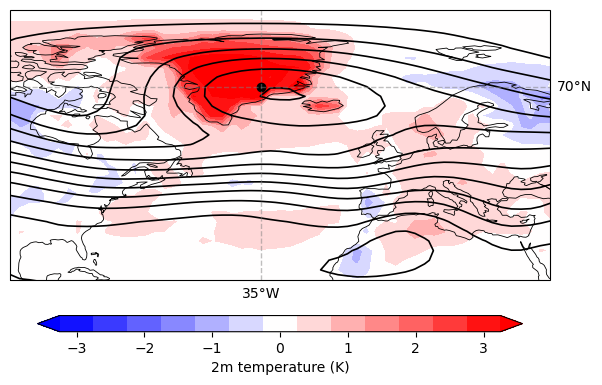

In [28]:
fig,ax = plt.subplots(nrows=1,ncols=1,figsize=(10,4),subplot_kw={'projection': ccrs.PlateCarree()})
title = ''
field = ma.masked_array(zg_comp,zg_comp==0)
extent =[-100,40,20,90] #Greenland
#extent =[-180,180,20,90] #Europe
ax.set_extent(extent, ccrs.PlateCarree())
ax.coastlines(linewidth = 0.6)
ax.plot(plon,plat,color='black', marker='o')
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, 
                color='gray', 
                alpha=0.5, 
                linestyle='--')
gl.xlocator = mticker.FixedLocator([plon])
gl.ylocator = mticker.FixedLocator([plat])
gl.xlabels_top = False
gl.ylabels_left = False
cont = ax.contour(lon,lat,field,
                    colors = 'black',
                    alpha =1.,
                    linewidths = 1.2,
                    levels = np.arange(4600,7200,40)
                    )
                    #cmap = "YlGnBu")
#c_range = np.array(np.arange(-np.amax(abs(anom_comp)),+np.amax(abs(anom_comp)),np.amax(abs(anom_comp))/8)) + np.array(np.amax(abs(anom_comp))/16)
c_range = np.arange(-3.25,3.35,0.5)
#ticks = np.array(np.arange(-np.amax(abs(anom_comp)),+np.amax(abs(anom_comp)),np.amax(abs(anom_comp))/4)) + np.array(np.amax(abs(anom_comp))/8)
ticks = np.arange(-3.,+3.1,1)
shadings = ax.contourf(lon,lat,anom_comp,
                      cmap='bwr',
                      extend = 'both', 
                      levels = c_range)
#cs_p = ax.contourf(lon,lat,t_st_anom,levels = 1,colors='none',hatches=['','...'])
fig.colorbar(shadings,ticks=ticks,label='2m temperature (K)',pad=0.1,orientation='horizontal',shrink=0.5,aspect=30)
ax.set_title('')
plt.tight_layout()
plt.show()
#plt.savefig('/Users/michelefilippucci/PLOTS/EGU/composite_greenland.png',dpi=300)
